# Program 37: Correlation Analysis of Study Time vs Exam Scores

**Scenario / Problem Statement**

Compute Pearson and Spearman correlations between student study time and exam scores, and visualize the trend.

Run the cells from top to bottom in Google Colab.

## 1. Import required libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


## 2. Load data and perform the analysis

Dataset loaded: FODS_Lab_Datasets_Q20_to_Q40.xlsx - Q37_Study_Exam_Corr.csv
Dataset shape: (50, 3)
Pearson Correlation Coefficient: 0.9441
Spearman Correlation Coefficient: 0.9379


,Student_ID,Study_Time_Hours,Exam_Score
0,STU-001,7.2,73.7
1,STU-002,10.4,89.3
2,STU-003,3.2,54.7
3,STU-004,11.3,94.1
4,STU-005,8.6,89.8


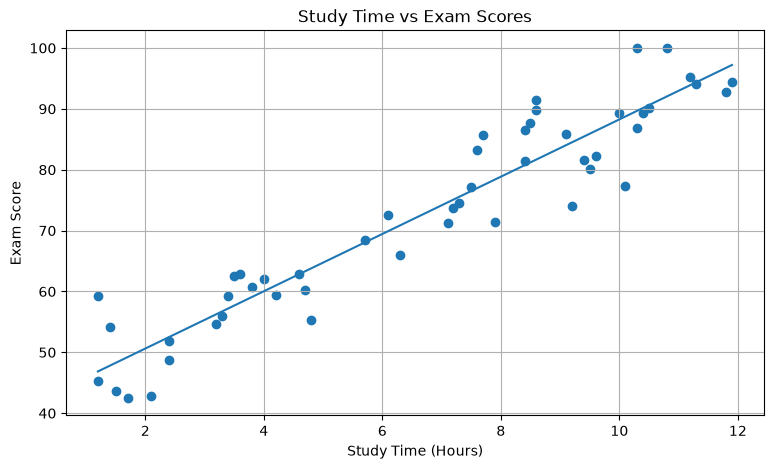

In [2]:
# Load the supplied CSV. In Colab, upload it if it is not already present.
from pathlib import Path
DATA_FILE = 'FODS_Lab_Datasets_Q20_to_Q40.xlsx - Q37_Study_Exam_Corr.csv'
if not Path(DATA_FILE).exists():
    try:
        from google.colab import files
        files.upload()
    except ImportError as exc:
        raise FileNotFoundError('FODS_Lab_Datasets_Q20_to_Q40.xlsx - Q37_Study_Exam_Corr.csv is missing; place the CSV beside this notebook.') from exc
df_raw = pd.read_csv(DATA_FILE, skiprows=3)
print("Dataset loaded:", DATA_FILE)
print("Dataset shape:", df_raw.shape)
display(df_raw.head())

df_raw["Study_Time_Hours"] = pd.to_numeric(df_raw["Study_Time_Hours"], errors="coerce")
df_raw["Exam_Score"] = pd.to_numeric(df_raw["Exam_Score"], errors="coerce")
data = df_raw.dropna(subset=["Study_Time_Hours", "Exam_Score"])

pearson = data["Study_Time_Hours"].corr(data["Exam_Score"], method="pearson")
spearman = data["Study_Time_Hours"].corr(data["Exam_Score"], method="spearman")
print(f"Pearson Correlation Coefficient: {pearson:.4f}")
print(f"Spearman Correlation Coefficient: {spearman:.4f}")

plt.figure(figsize=(9, 5))
plt.scatter(data["Study_Time_Hours"], data["Exam_Score"])
m, b = np.polyfit(data["Study_Time_Hours"], data["Exam_Score"], 1)
x_line = np.linspace(data["Study_Time_Hours"].min(), data["Study_Time_Hours"].max(), 100)
plt.plot(x_line, m*x_line+b)
plt.title("Study Time vs Exam Scores")
plt.xlabel("Study Time (Hours)")
plt.ylabel("Exam Score")
plt.grid(True)
plt.show()

## 3. Result

The output above displays the required analysis, model results, or visualization.